In [72]:
import pandas as pd

In [73]:
ecomerce=pd.read_csv(r'C:\Users\Loq\OneDrive\Desktop\project\indian_ecommerce_sales_5000.csv')
ecomerce

,order_id,order_date,state,city,product_category,product_price,quantity,discount_percent,payment_method,customer_age,customer_rating,order_status,total_amount
0,ORD100000,2023-12-27,Uttar Pradesh,Chennai,Grocery,30598.66,4,19.31,Wallet,19,1.7,Delivered,98760.24
1,ORD100001,2023-09-04,Uttar Pradesh,Delhi,Beauty,8909.63,2,7.32,Net Banking,38,1.1,Delivered,16514.89
2,ORD100002,2024-10-12,Rajasthan,Ahmedabad,Electronics,38378.88,4,38.94,Wallet,48,1.5,Returned,93736.58
3,ORD100003,2023-12-14,Telangana,Lucknow,Beauty,17227.08,3,39.02,Wallet,25,1.5,Cancelled,31515.22
4,ORD100004,2023-08-06,West Bengal,Kolkata,Toys,11263.39,3,33.70,UPI,55,3.9,Delivered,22402.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,ORD104995,2023-05-22,Punjab,Ahmedabad,Toys,2685.82,1,32.97,Credit Card,23,4.7,Returned,1800.31
4996,ORD104996,2023-07-06,Delhi,Jaipur,Toys,1677.32,2,3.81,Wallet,50,3.0,Delivered,3226.83
4997,ORD104997,2023-11-18,Tamil Nadu,Delhi,Grocery,15277.15,3,3.66,Wallet,38,3.2,Returned,44154.02
4998,ORD104998,2023-11-28,Karnataka,Gurugram,Fashion,33709.18,3,17.66,Net Banking,56,3.0,Delivered,83268.42


In [74]:
ecomerce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   object 
 1   order_date        5000 non-null   object 
 2   state             5000 non-null   object 
 3   city              5000 non-null   object 
 4   product_category  5000 non-null   object 
 5   product_price     5000 non-null   float64
 6   quantity          5000 non-null   int64  
 7   discount_percent  5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   customer_age      5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  order_status      5000 non-null   object 
 12  total_amount      5000 non-null   float64
dtypes: float64(4), int64(2), object(7)
memory usage: 507.9+ KB


In [75]:
ecomerce.isnull().sum()

order_id            0
order_date          0
state               0
city                0
product_category    0
product_price       0
quantity            0
discount_percent    0
payment_method      0
customer_age        0
customer_rating     0
order_status        0
total_amount        0
dtype: int64

In [76]:
ecomerce.columns  

Index(['order_id', 'order_date', 'state', 'city', 'product_category',
       'product_price', 'quantity', 'discount_percent', 'payment_method',
       'customer_age', 'customer_rating', 'order_status', 'total_amount'],
      dtype='object')

In [77]:
ecomerce=ecomerce.rename(
    columns={'state':'State',
            'city':'City'}
)
ecomerce

,order_id,order_date,State,City,product_category,product_price,quantity,discount_percent,payment_method,customer_age,customer_rating,order_status,total_amount
0,ORD100000,2023-12-27,Uttar Pradesh,Chennai,Grocery,30598.66,4,19.31,Wallet,19,1.7,Delivered,98760.24
1,ORD100001,2023-09-04,Uttar Pradesh,Delhi,Beauty,8909.63,2,7.32,Net Banking,38,1.1,Delivered,16514.89
2,ORD100002,2024-10-12,Rajasthan,Ahmedabad,Electronics,38378.88,4,38.94,Wallet,48,1.5,Returned,93736.58
3,ORD100003,2023-12-14,Telangana,Lucknow,Beauty,17227.08,3,39.02,Wallet,25,1.5,Cancelled,31515.22
4,ORD100004,2023-08-06,West Bengal,Kolkata,Toys,11263.39,3,33.70,UPI,55,3.9,Delivered,22402.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,ORD104995,2023-05-22,Punjab,Ahmedabad,Toys,2685.82,1,32.97,Credit Card,23,4.7,Returned,1800.31
4996,ORD104996,2023-07-06,Delhi,Jaipur,Toys,1677.32,2,3.81,Wallet,50,3.0,Delivered,3226.83
4997,ORD104997,2023-11-18,Tamil Nadu,Delhi,Grocery,15277.15,3,3.66,Wallet,38,3.2,Returned,44154.02
4998,ORD104998,2023-11-28,Karnataka,Gurugram,Fashion,33709.18,3,17.66,Net Banking,56,3.0,Delivered,83268.42


In [78]:
import numpy as np

In [79]:
state=np.unique(ecomerce['State'])
city=np.unique(ecomerce['City'])
print(state)
print(city)

['Delhi' 'Gujarat' 'Haryana' 'Karnataka' 'Kerala' 'Maharashtra' 'Punjab'
 'Rajasthan' 'Tamil Nadu' 'Telangana' 'Uttar Pradesh' 'West Bengal']
['Ahmedabad' 'Bengaluru' 'Chandigarh' 'Chennai' 'Delhi' 'Gurugram'
 'Hyderabad' 'Jaipur' 'Kochi' 'Kolkata' 'Lucknow' 'Mumbai']


In [80]:
ecomerce['City']=ecomerce['City'].replace({
    'Bengaluru':'Bangalore'
})

In [81]:
ecomerce.columns = ecomerce.columns.str.strip().str.title()

In [82]:
ecomerce.drop_duplicates(inplace=True)

In [83]:
ecomerce['Order_Date'] = pd.to_datetime(ecomerce['Order_Date'])

ecomerce['Year'] = ecomerce['Order_Date'].dt.year
ecomerce['Month'] = ecomerce['Order_Date'].dt.month

ecomerce.drop('Order_Date', axis=1, inplace=True)

In [84]:
ecomerce

,Order_Id,State,City,Product_Category,Product_Price,Quantity,Discount_Percent,Payment_Method,Customer_Age,Customer_Rating,Order_Status,Total_Amount,Year,Month
0,ORD100000,Uttar Pradesh,Chennai,Grocery,30598.66,4,19.31,Wallet,19,1.7,Delivered,98760.24,2023,12
1,ORD100001,Uttar Pradesh,Delhi,Beauty,8909.63,2,7.32,Net Banking,38,1.1,Delivered,16514.89,2023,9
2,ORD100002,Rajasthan,Ahmedabad,Electronics,38378.88,4,38.94,Wallet,48,1.5,Returned,93736.58,2024,10
3,ORD100003,Telangana,Lucknow,Beauty,17227.08,3,39.02,Wallet,25,1.5,Cancelled,31515.22,2023,12
4,ORD100004,West Bengal,Kolkata,Toys,11263.39,3,33.70,UPI,55,3.9,Delivered,22402.88,2023,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,ORD104995,Punjab,Ahmedabad,Toys,2685.82,1,32.97,Credit Card,23,4.7,Returned,1800.31,2023,5
4996,ORD104996,Delhi,Jaipur,Toys,1677.32,2,3.81,Wallet,50,3.0,Delivered,3226.83,2023,7
4997,ORD104997,Tamil Nadu,Delhi,Grocery,15277.15,3,3.66,Wallet,38,3.2,Returned,44154.02,2023,11
4998,ORD104998,Karnataka,Gurugram,Fashion,33709.18,3,17.66,Net Banking,56,3.0,Delivered,83268.42,2023,11


In [85]:
ecomerce.dtypes

Order_Id             object
State                object
City                 object
Product_Category     object
Product_Price       float64
Quantity              int64
Discount_Percent    float64
Payment_Method       object
Customer_Age          int64
Customer_Rating     float64
Order_Status         object
Total_Amount        float64
Year                  int32
Month                 int32
dtype: object

In [86]:
ecomerce.to_csv("ecomerce_cleaned_data.csv", index=False)

In [87]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Total amount vs sales')

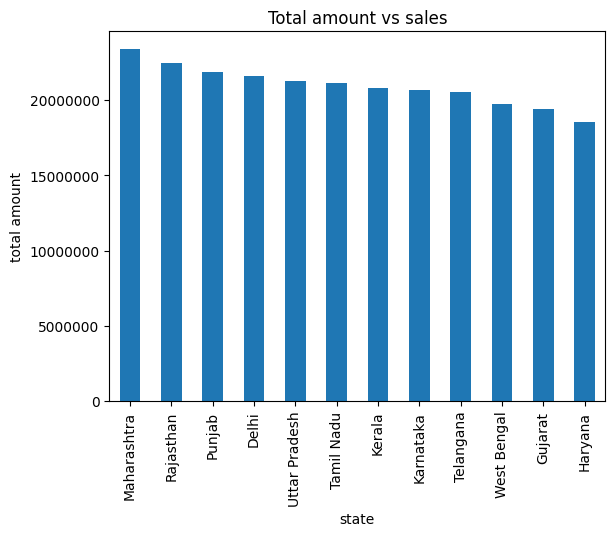

In [88]:
ecomerce.groupby('State')['Total_Amount'].sum().sort_values(ascending=False).plot(kind='bar')
plt.ticklabel_format(style='plain',axis='y')
plt.ylabel('total amount')
plt.xlabel('state')
plt.title('Total amount vs sales')

<Axes: ylabel='Total_Amount'>

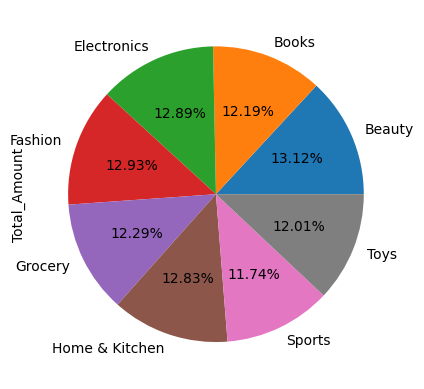

In [89]:
ecomerce.groupby('Product_Category')['Total_Amount'].sum().plot(kind='pie', autopct='%1.2f%%')

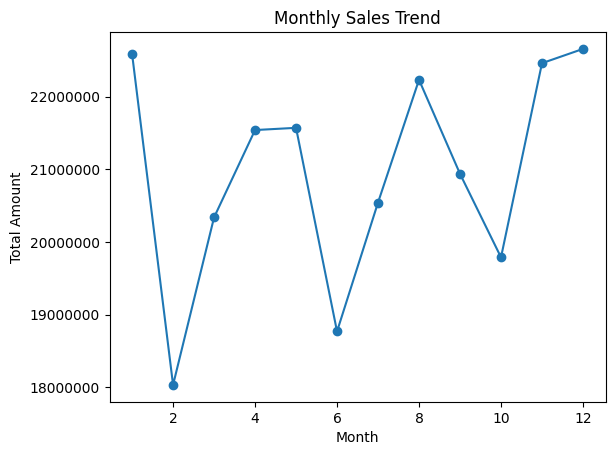

In [90]:
monthly_sales=ecomerce.groupby(['Month'])['Total_Amount'].sum().reset_index()
plt.plot(monthly_sales['Month'], monthly_sales['Total_Amount'], marker='o')
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel("Month")
plt.ylabel("Total Amount")
plt.title("Monthly Sales Trend")
plt.show()

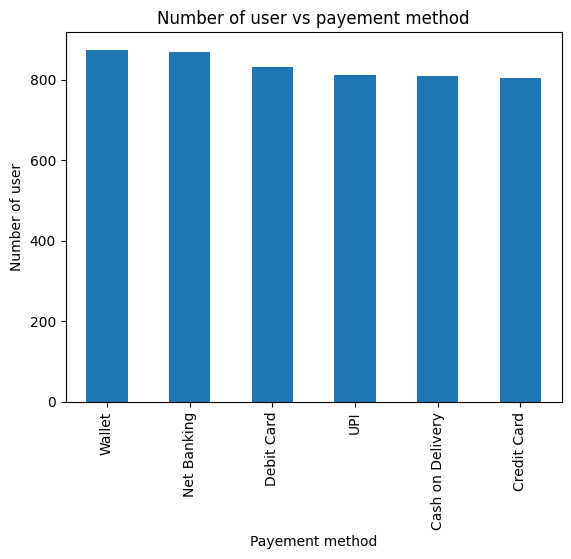

In [91]:
ecomerce['Payment_Method'].value_counts().plot(kind='bar')
plt.xlabel('Payement method')
plt.ylabel('Number of user')
plt.title('Number of user vs payement method')
plt.show()


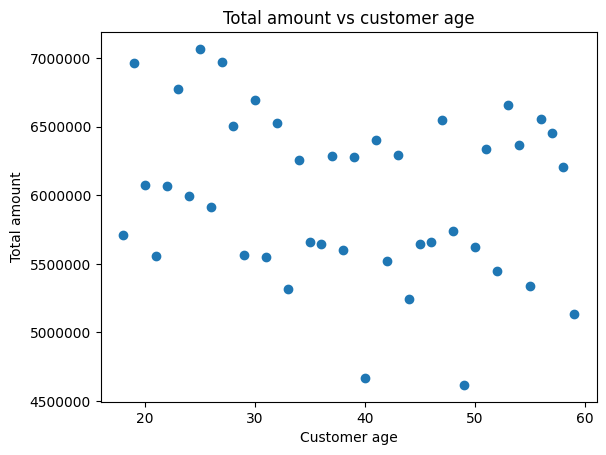

In [92]:
customer_age=ecomerce.groupby('Customer_Age')['Total_Amount'].sum()
plt.scatter(customer_age.index,customer_age.values)
plt.xlabel('Customer age')
plt.ylabel('Total amount')
plt.title('Total amount vs customer age')
plt.ticklabel_format(style='plain',axis='y')
plt.show()

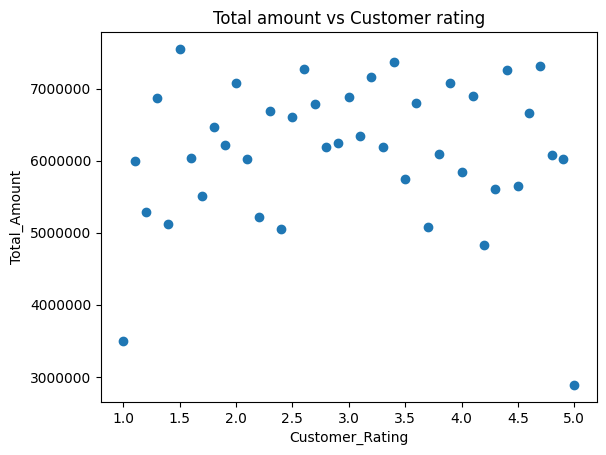

In [93]:
rating=ecomerce.groupby('Customer_Rating')['Total_Amount'].sum()
plt.scatter(x=rating.index,y=rating.values)
plt.xlabel('Customer_Rating')
plt.ylabel('Total_Amount')
plt.title('Total amount vs Customer rating')
plt.ticklabel_format(style='plain',axis='y')
plt.show()

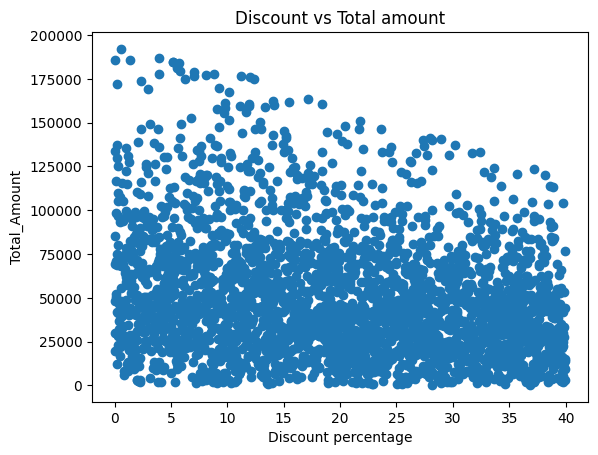

In [94]:
discount=ecomerce.groupby('Discount_Percent')['Total_Amount'].mean()
plt.scatter(x=discount.index, y=discount.values)
plt.xlabel('Discount percentage')
plt.ylabel('Total_Amount')
plt.title('Discount vs Total amount')
plt.ticklabel_format(style='plain',axis='y')
plt.show()